# 00 — Explore ATRW re-ID

Goals:
1. How many distinct tiger IDs? (Is it 92?)
2. Images per tiger: min / median / max. Evenly spread or not?
3. Is there any way to tell which **video clip** an image came from?


## Setup
Works in Colab or locally. In Colab this downloads the data (~1 min); re-run each session.

In [1]:
import os
from pathlib import Path

IN_COLAB = "google.colab" in str(get_ipython())
DATA = Path("data/atrw") if IN_COLAB else Path("../data/atrw")

if IN_COLAB and not (DATA / "atrw_reid_train").exists():
    base = "https://storage.googleapis.com/public-datasets-lila/cvwc2019/train"
    for name in ["atrw_reid_train", "atrw_anno_reid_train"]:
        os.makedirs(DATA / name, exist_ok=True)
        !wget -q {base}/{name}.tar.gz -O {DATA}/{name}.tar.gz
        !tar -xzf {DATA}/{name}.tar.gz -C {DATA}/{name} && rm {DATA}/{name}.tar.gz

print(sorted(p.name for p in DATA.iterdir()))

['atrw_anno_reid_train', 'atrw_reid_train']


In [2]:
import pandas as pd

df = pd.read_csv(DATA / "atrw_anno_reid_train/reid_list_train.csv",
                 header=None, names=["tiger_id", "filename"])
df.head()

,tiger_id,filename
0,250,003597.jpg
1,256,003523.jpg
2,171,003900.jpg
3,247,002636.jpg
4,238,002249.jpg


## Q1: how many distinct tigers?

In [3]:

n_tigers = df["tiger_id"].nunique()
print(f"There are {n_tigers} distinct tigers.")


There are 107 distinct tigers.


## Q2: images per tiger

Min: 10, median: 13.0, max: 98


<Axes: >

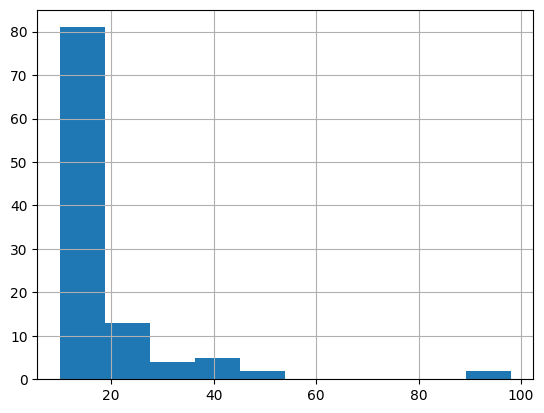

In [4]:
counts = df["tiger_id"].value_counts()
print(f"Min: {counts.min()}, median: {counts.median()}, max: {counts.max()}")
counts.hist()


## Q3: any clip information?
Read the annotation README, then look at filenames. Are they sequential? Do neighboring numbers look like the same tiger?

In [5]:
print(open(DATA / "atrw_anno_reid_train/README.md").read())

reid_list_train.csv: Containing id and image file name. Format: id, file name.
reid_keypoints_train.json: Containing the keypoints of images. Format: {img_file_name(str):keypoints(array)}, keypoints:[x1,y1,v1,x2,y2,v2...](as defined in MSCOCO)



In [11]:
from PIL import Image

IMG = DATA / "atrw_reid_train/train"

s = df.sort_values("filename").reset_index(drop=True)
same_as_previous = (s["tiger_id"] == s["tiger_id"].shift())
print("fraction same as previous:", same_as_previous.mean())

print("labeled rows in CSV:", len(df))
print("images in train folder:", len(list(IMG.glob("*.jpg"))))


fraction same as previous: 0.012718600953895072
labeled rows in CSV: 1887
images in train folder: 3392


1. **Unique IDs:** 107, not 92. Why: IDS are not just a tiger the IDS are each side of a tiger (check the ATRW paper; hint: left vs right flanks)

2. **Images per ID:** min 10, median 13, max 98. The distribution is skewed (even / skewed: a few IDs have many more images).
   Out of 3,392 images in train/, only 1,887 are labeled. The other 1,505 have no ID or keypoints, so we ignore them.

3. **Clip info:** none. The README says the CSV is just `id, filename`, and the keypoint JSON is pose only.
   Sorted filenames share an ID with the previous file only 1.3% of the time (about what random order gives), so the filenames are shuffled.
   → We need to rebuild "pseudo-clips" by grouping near-duplicate images within each ID before splitting.
